# PN Detection U-Net — v3.0 controlled retraining

This notebook deliberately keeps the **same U-Net architecture**, CenterNet-style
focal loss, optimizer setup, and `val_loss` checkpoint/early-stopping criterion
as v2.0.

The paired v5.0 synthesizer changes the training distribution (morphology
mixture, crowding, PN prevalence, magnitude sampling, spectral scatter, and
1.5-pixel target sigma). This notebook therefore avoids architecture/loss
changes so the effect of the new synthetic data can be interpreted cleanly.

Source-level metrics are still logged for diagnosis, but they do **not** select
the checkpoint. The final operating threshold is still chosen by a validation
threshold sweep after the best-`val_loss` model is reloaded.


In [1]:
import os
SEED=42
os.environ["PYTHONHASHSEED"]=str(SEED)
os.environ["TF_DETERMINISTIC_OPS"]="1"

from pathlib import Path
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from scipy.ndimage import maximum_filter

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("TensorFlow version:",tf.__version__)

I0000 00:00:1789235341.411158   29058 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789235341.457760   29058 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.21.0


In [2]:
DATA_PATH=Path("all_PN_10000_grouped_norm_v5.0.npz")
MODEL_PATH=Path("best_PN_UNet_focal_all_grouped_v3.0.keras")
NORM_PATH=Path("PN_UNet_normalization_v3.0.npz")
SPLIT_PATH=Path("PN_UNet_split_manifest_v3.0.npz")
CONFIG_PATH=Path("PN_UNet_training_config_v3.0.json")

FLUX_SCALE=1e18
ASINH_PERCENTILE=90.0
BATCH_SIZE=32
LEARNING_RATE=3e-4
WEIGHT_DECAY=1e-5
CLIPNORM=1.0
MAX_EPOCHS=100

PEAK_THRESHOLD=0.30
MIN_DISTANCE=3
MATCH_TOLERANCE=1.0

COMPACT_NEGATIVE_TYPES=["compact_nonpn","compact_non-pn","nonpn_compact","hard_negative"]
BACKGROUND_TYPES=["background","empty","blank"]


## Load dataset

In [3]:
data=np.load(DATA_PATH,allow_pickle=True)
X=data["X"].astype(np.float32)
Y=data["Y"].astype(np.float32)
line_names=data["line_names"]
saved_channel_means=data["channel_means"].astype(np.float32)
saved_channel_stds=data["channel_stds"].astype(np.float32)
metadata=json.loads(data["metadata_json"].item())

group_key=next((k for k in ("group_ids","parent_ids","split_group_ids") if k in data.files),None)
type_key=next((k for k in ("sample_types","sample_type","source_types") if k in data.files),None)

if group_key is None:
    raise KeyError("Dataset is missing leakage-safe group IDs.")
if type_key is None:
    raise KeyError("Dataset is missing sample_types.")

group_ids=np.asarray(data[group_key]).astype(str)
sample_types=np.char.lower(np.asarray(data[type_key]).astype(str))

if len(group_ids)!=len(X) or len(sample_types)!=len(X):
    raise ValueError("group_ids and sample_types must have length N.")

print("Original X shape:",X.shape)
print("Original Y shape:",Y.shape)
print("Lines:",line_names)
print("Unique groups:",len(np.unique(group_ids)))
print("Sample types:")
for name,count in zip(*np.unique(sample_types,return_counts=True)):
    print(f"  {name}: {count}")

Original X shape: (10000, 4, 64, 64)
Original Y shape: (10000, 1, 64, 64)
Lines: ['Hbeta' 'OIII5007' 'Halpha' 'NII6584']
Unique groups: 139
Sample types:
  background: 334
  compact_nonpn: 4623
  pn: 5043


In [4]:
X=np.transpose(X,(0,2,3,1))
Y=np.transpose(Y,(0,2,3,1))

assert X.ndim==4 and X.shape[-1]==4
assert Y.ndim==4 and Y.shape[-1]==1
assert X.shape[1:3]==(64,64)
assert Y.shape[1:3]==(64,64)

print("Transposed X shape:",X.shape)
print("Transposed Y shape:",Y.shape)

Transposed X shape: (10000, 64, 64, 4)
Transposed Y shape: (10000, 64, 64, 1)


## Recover unstandardized inputs if needed

In [5]:
current_means=X.mean(axis=(0,1,2),dtype=np.float64)
current_stds=X.std(axis=(0,1,2),dtype=np.float64)
already_standardized=np.all(np.abs(current_means)<0.1) and np.all(np.abs(current_stds-1.0)<0.1)

print("Current means:",current_means)
print("Current stds:",current_stds)
print("Looks already standardized:",already_standardized)

if already_standardized:
    X=(X*saved_channel_stds[None,None,None,:]+saved_channel_means[None,None,None,:]).astype(np.float32)
    print("Recovered approximately raw inputs using saved dataset statistics.")
else:
    X=X.astype(np.float32,copy=True)
    print("Inputs already appear unstandardized.")

if not np.all(np.isfinite(X)):
    raise ValueError("X contains NaN or Inf values.")
if not np.all(np.isfinite(Y)):
    raise ValueError("Y contains NaN or Inf values.")

Current means: [ 1.72517473e-10  1.85404728e-09  1.22615670e-10 -2.98605746e-11]
Current stds: [1.         0.99999999 1.         1.        ]
Looks already standardized: True
Recovered approximately raw inputs using saved dataset statistics.


## Inspect one sample

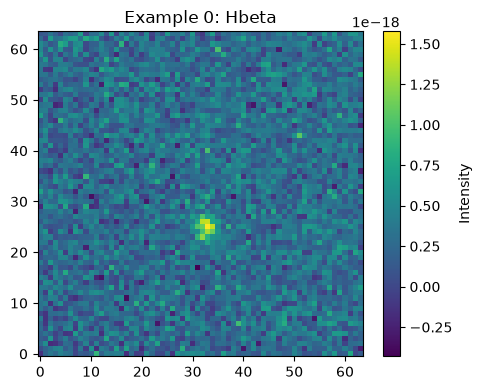

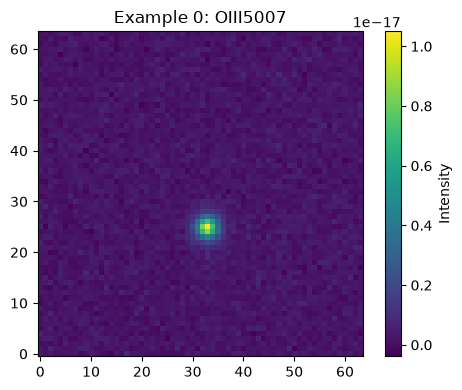

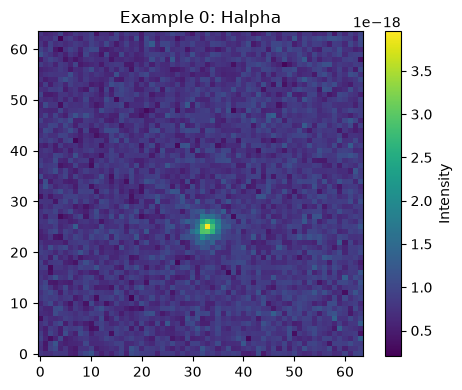

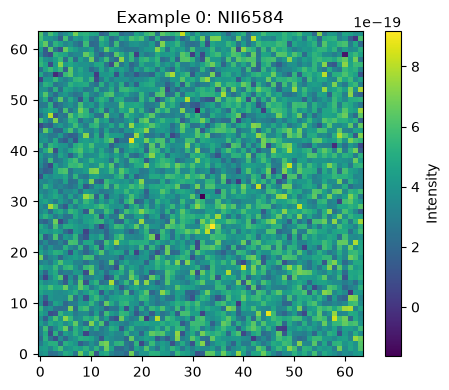

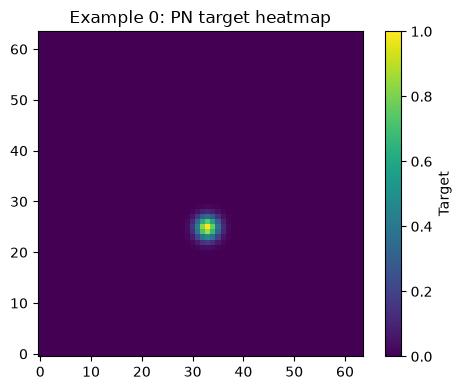

In [6]:
i=0
for c,name in enumerate(line_names):
    plt.figure(figsize=(5,4))
    plt.imshow(X[i,:,:,c],origin="lower")
    plt.colorbar(label="Intensity")
    plt.title(f"Example {i}: {name}")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(5,4))
plt.imshow(Y[i,:,:,0],origin="lower")
plt.colorbar(label="Target")
plt.title(f"Example {i}: PN target heatmap")
plt.tight_layout()
plt.show()

## Leakage-safe train / validation / test split

In [7]:
has_pn=np.any(Y>=0.999,axis=(1,2,3)).astype(np.int32)

def best_group_holdout(indices,groups,labels,holdout_fraction,seed,n_trials=200):
    indices=np.asarray(indices)
    groups=np.asarray(groups)
    labels=np.asarray(labels)
    if len(np.unique(groups[indices]))<2:
        raise ValueError("Not enough independent groups for leakage-safe splitting.")
    overall_pos=labels[indices].mean()
    target_n=holdout_fraction*len(indices)
    best=None
    for t in range(n_trials):
        splitter=GroupShuffleSplit(n_splits=1,test_size=holdout_fraction,random_state=seed+t)
        keep_local,hold_local=next(splitter.split(np.zeros(len(indices)),labels[indices],groups=groups[indices]))
        keep_idx=indices[keep_local]
        hold_idx=indices[hold_local]
        hold_error=abs(len(hold_idx)-target_n)/max(len(indices),1)
        balance_error=abs(labels[keep_idx].mean()-overall_pos)+abs(labels[hold_idx].mean()-overall_pos)
        score=hold_error+balance_error
        if best is None or score<best[0]:
            best=(score,keep_idx,hold_idx)
    return best[1],best[2]

all_idx=np.arange(len(X))
train_idx,temp_idx=best_group_holdout(all_idx,group_ids,has_pn,0.20,SEED)
val_idx,test_idx=best_group_holdout(temp_idx,group_ids,has_pn,0.50,SEED+1000)

train_groups=set(group_ids[train_idx])
val_groups=set(group_ids[val_idx])
test_groups=set(group_ids[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

types_train=sample_types[train_idx]
types_val=sample_types[val_idx]
types_test=sample_types[test_idx]

def split_report(name,idx,types):
    compact=np.isin(types,COMPACT_NEGATIVE_TYPES)
    background=np.isin(types,BACKGROUND_TYPES)
    print(f"{name:5s}: N={len(idx):5d} | groups={len(np.unique(group_ids[idx])):4d} | PN-containing={has_pn[idx].mean():.3f} | compact non-PN={compact.sum():4d} | background={background.sum():4d}")

print("Leakage-safe split:")
split_report("Train",train_idx,types_train)
split_report("Val",val_idx,types_val)
split_report("Test",test_idx,types_test)

negative_train=~has_pn[train_idx].astype(bool)
compact_negative_train=negative_train&np.isin(types_train,COMPACT_NEGATIVE_TYPES)

if negative_train.sum()==0:
    raise ValueError("Training set contains no negative samples.")

compact_fraction=compact_negative_train.sum()/negative_train.sum()
print(f"Fraction of training negatives that are compact non-PNe: {compact_fraction:.3f}")

if compact_fraction<0.5:
    print("WARNING: realistic compact non-PNe do not dominate the negative training set.")

Leakage-safe split:
Train: N= 8027 | groups= 111 | PN-containing=0.504 | compact non-PN=3708 | background= 272
Val  : N=  989 | groups=  14 | PN-containing=0.505 | compact non-PN= 461 | background=  29
Test : N=  984 | groups=  14 | PN-containing=0.505 | compact non-PN= 454 | background=  33
Fraction of training negatives that are compact non-PNe: 0.932


## Robust asinh preprocessing + train-only standardization

In [8]:
def calculate_asinh_scale(x,indices,percentile):
    scales=np.zeros(x.shape[-1],dtype=np.float64)
    for c in range(x.shape[-1]):
        values=x[indices,:,:,c].astype(np.float32)*np.float32(FLUX_SCALE)
        values=np.abs(values[np.isfinite(values)])
        scales[c]=np.percentile(values,percentile)
        if not np.isfinite(scales[c]) or scales[c]<=0:
            raise ValueError(f"Invalid asinh scale for channel {c}: {scales[c]}")
    return scales

asinh_scale=calculate_asinh_scale(X,train_idx,ASINH_PERCENTILE)
asinh_scale32=asinh_scale.astype(np.float32)

def asinh_transform(x):
    x_scaled=x.astype(np.float32)*np.float32(FLUX_SCALE)
    return np.arcsinh(x_scaled/asinh_scale32[None,None,None,:]).astype(np.float32)

X_train_transformed=asinh_transform(X[train_idx])
channel_means=np.mean(X_train_transformed,axis=(0,1,2),dtype=np.float64)
channel_stds=np.std(X_train_transformed,axis=(0,1,2),dtype=np.float64)

if np.any(~np.isfinite(channel_means)):
    raise ValueError(f"Invalid channel means: {channel_means}")
if np.any(~np.isfinite(channel_stds)) or np.any(channel_stds<=0):
    raise ValueError(f"Invalid channel standard deviations: {channel_stds}")

mean32=channel_means.astype(np.float32)
std32=channel_stds.astype(np.float32)

X_train=((X_train_transformed-mean32[None,None,None,:])/std32[None,None,None,:]).astype(np.float32)
del X_train_transformed

def normalize_indices(indices):
    transformed=asinh_transform(X[indices])
    return ((transformed-mean32[None,None,None,:])/std32[None,None,None,:]).astype(np.float32)

X_val=normalize_indices(val_idx)
X_test=normalize_indices(test_idx)
Y_train=Y[train_idx].astype(np.float32)
Y_val=Y[val_idx].astype(np.float32)
Y_test=Y[test_idx].astype(np.float32)

print("FLUX_SCALE:",FLUX_SCALE)
print("ASINH_PERCENTILE:",ASINH_PERCENTILE)
print("ASINH scales:",asinh_scale)
print("Train-only transformed means:",channel_means)
print("Train-only transformed stds:",channel_stds)
print("Normalized train means:",X_train.mean(axis=(0,1,2),dtype=np.float64))
print("Normalized train stds:",X_train.std(axis=(0,1,2),dtype=np.float64))

FLUX_SCALE: 1e+18
ASINH_PERCENTILE: 90.0
ASINH scales: [ 2.43136716  1.46427071 10.6684761   5.48054123]
Train-only transformed means: [0.46611421 0.48516408 0.41826381 0.38846497]
Train-only transformed stds: [0.51285611 0.42062526 0.52631069 0.45978032]
Normalized train means: [-1.98397035e-08  2.10153726e-08 -2.29747387e-08 -2.68080683e-08]
Normalized train stds: [0.99999997 0.99999999 1.00000001 0.99999999]


In [9]:
np.savez(
    SPLIT_PATH,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    train_groups=np.asarray(sorted(train_groups)),
    val_groups=np.asarray(sorted(val_groups)),
    test_groups=np.asarray(sorted(test_groups))
)
print("Saved split manifest:",SPLIT_PATH)

Saved split manifest: PN_UNet_split_manifest_v3.0.npz


## Deterministic augmentation and tf.data pipelines

In [10]:
def augment(index,x,y):
    index=tf.cast(index,tf.int32)
    seed=tf.stack([tf.cast(SEED,tf.int32),index])
    seeds=tf.random.experimental.stateless_split(seed,3)

    k=tf.random.stateless_uniform([],seed=seeds[0],minval=0,maxval=4,dtype=tf.int32)
    x=tf.image.rot90(x,k)
    y=tf.image.rot90(y,k)

    do_lr=tf.random.stateless_uniform([],seed=seeds[1])>0.5
    x=tf.cond(do_lr,lambda:tf.image.flip_left_right(x),lambda:x)
    y=tf.cond(do_lr,lambda:tf.image.flip_left_right(y),lambda:y)

    do_ud=tf.random.stateless_uniform([],seed=seeds[2])>0.5
    x=tf.cond(do_ud,lambda:tf.image.flip_up_down(x),lambda:x)
    y=tf.cond(do_ud,lambda:tf.image.flip_up_down(y),lambda:y)
    return x,y

options=tf.data.Options()
options.experimental_deterministic=True

train_ds=(
    tf.data.Dataset.from_tensor_slices((X_train,Y_train))
    .shuffle(len(X_train),seed=SEED,reshuffle_each_iteration=True)
    .enumerate()
    .map(lambda idx,data:augment(idx,data[0],data[1]),num_parallel_calls=tf.data.AUTOTUNE,deterministic=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(options)
)

val_ds=(
    tf.data.Dataset.from_tensor_slices((X_val,Y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(options)
)

test_ds=(
    tf.data.Dataset.from_tensor_slices((X_test,Y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
    .with_options(options)
)

I0000 00:00:1789235355.801586   29058 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


## U-Net model

In [11]:
def conv_block(x,filters):
    x=layers.Conv2D(filters,3,padding="same",use_bias=False,kernel_initializer="he_normal")(x)
    x=layers.BatchNormalization()(x)
    x=layers.ReLU()(x)
    x=layers.Conv2D(filters,3,padding="same",use_bias=False,kernel_initializer="he_normal")(x)
    x=layers.BatchNormalization()(x)
    x=layers.ReLU()(x)
    return x

def build_unet(input_shape=(64,64,4)):
    inputs=keras.Input(shape=input_shape)
    c1=conv_block(inputs,32)
    p1=layers.MaxPooling2D((2,2))(c1)
    c2=conv_block(p1,64)
    p2=layers.MaxPooling2D((2,2))(c2)
    c3=conv_block(p2,128)
    p3=layers.MaxPooling2D((2,2))(c3)
    b=conv_block(p3,256)
    b=layers.Dropout(0.20)(b)
    u3=layers.Conv2DTranspose(128,2,strides=2,padding="same")(b)
    u3=layers.Concatenate()([u3,c3])
    c4=conv_block(u3,128)
    u2=layers.Conv2DTranspose(64,2,strides=2,padding="same")(c4)
    u2=layers.Concatenate()([u2,c2])
    c5=conv_block(u2,64)
    u1=layers.Conv2DTranspose(32,2,strides=2,padding="same")(c5)
    u1=layers.Concatenate()([u1,c1])
    c6=conv_block(u1,32)
    outputs=layers.Conv2D(1,1,activation="sigmoid",name="pn_heatmap")(c6)
    return keras.Model(inputs,outputs,name="PN_UNet")

## Focal loss

In [12]:
@tf.keras.utils.register_keras_serializable()
def center_focal_loss(y_true,y_pred):
    eps=1e-6
    y_pred=tf.clip_by_value(y_pred,eps,1.0-eps)
    positive=tf.cast(y_true>=0.999,tf.float32)
    negative=tf.cast(y_true<0.999,tf.float32)
    negative_weights=tf.pow(1.0-y_true,4.0)
    positive_loss=-tf.math.log(y_pred)*tf.pow(1.0-y_pred,2.0)*positive
    negative_loss=-tf.math.log(1.0-y_pred)*tf.pow(y_pred,2.0)*negative_weights*negative
    num_positive=tf.reduce_sum(positive)
    total_loss=tf.reduce_sum(positive_loss)+tf.reduce_sum(negative_loss)
    return total_loss/tf.maximum(num_positive,1.0)

## Source-level detection metrics

In [13]:
def find_pn_centers(heatmap,threshold=0.30,min_distance=3):
    size=2*min_distance+1
    local_max=heatmap==maximum_filter(heatmap,size=size,mode="constant")
    detected=local_max&(heatmap>=threshold)
    y,x=np.where(detected)
    scores=heatmap[y,x]
    order=np.argsort(scores)[::-1]
    return np.column_stack([x[order],y[order],scores[order]])

def find_true_centers(target,threshold=0.999,min_distance=1):
    size=2*min_distance+1
    local_max=target==maximum_filter(target,size=size,mode="constant")
    detected=local_max&(target>=threshold)
    y,x=np.where(detected)
    return np.column_stack([x,y]).astype(np.float32)

def match_detections(predicted,true_centers,tolerance=1.0):
    if len(predicted)==0:
        return 0,0,len(true_centers),[]
    if len(true_centers)==0:
        return 0,len(predicted),0,[]
    pred_xy=np.asarray(predicted[:,:2],dtype=np.float32)
    true_xy=np.asarray(true_centers,dtype=np.float32)
    used_true=set()
    tp=0
    localization_errors=[]
    for px,py in pred_xy:
        distances=np.sqrt((true_xy[:,0]-px)**2+(true_xy[:,1]-py)**2)
        for j in np.argsort(distances):
            if distances[j]>tolerance:
                break
            if j not in used_true:
                used_true.add(j)
                tp+=1
                localization_errors.append(float(distances[j]))
                break
    fp=len(pred_xy)-tp
    fn=len(true_xy)-tp
    return tp,fp,fn,localization_errors

def evaluate_detector(model,X_eval,Y_eval,threshold=0.30,min_distance=3,match_tolerance=1.0,verbose=0):
    predictions=model.predict(X_eval,batch_size=BATCH_SIZE,verbose=verbose)
    total_tp=total_fp=total_fn=0
    total_tn=total_negative_images=total_negative_images_with_fp=0
    all_errors=[]
    for pred_map,true_map in zip(predictions,Y_eval):
        pred_centers=find_pn_centers(pred_map[:,:,0],threshold,min_distance)
        true_centers=find_true_centers(true_map[:,:,0])
        if len(true_centers)==0:
            total_negative_images+=1
            if len(pred_centers)==0:
                total_tn+=1
            else:
                total_negative_images_with_fp+=1
        tp,fp,fn,errors=match_detections(pred_centers,true_centers,match_tolerance)
        total_tp+=tp
        total_fp+=fp
        total_fn+=fn
        all_errors.extend(errors)
    precision=total_tp/(total_tp+total_fp) if total_tp+total_fp else 0.0
    recall=total_tp/(total_tp+total_fn) if total_tp+total_fn else 0.0
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
    specificity=total_tn/total_negative_images if total_negative_images else np.nan
    fp_image_rate=total_negative_images_with_fp/total_negative_images if total_negative_images else np.nan
    errors=np.asarray(all_errors,dtype=np.float32)
    return {
        "TP":total_tp,
        "FP":total_fp,
        "FN":total_fn,
        "TN":total_tn,
        "negative_images":total_negative_images,
        "negative_images_with_FP":total_negative_images_with_fp,
        "specificity":specificity,
        "false_positive_image_rate":fp_image_rate,
        "precision":precision,
        "recall":recall,
        "f1":f1,
        "mean_localization_error":float(np.mean(errors)) if len(errors) else np.nan,
        "median_localization_error":float(np.median(errors)) if len(errors) else np.nan,
        "rmse_localization_error":float(np.sqrt(np.mean(errors**2))) if len(errors) else np.nan,
        "std_localization_error":float(np.std(errors)) if len(errors) else np.nan,
        "localization_errors":errors
    }

def negative_subset_fp_rate(model,X_subset,Y_subset,type_subset,threshold):
    pred_all=model.predict(X_subset,batch_size=BATCH_SIZE,verbose=0)
    rows=[]
    for target_type,aliases in {"compact_nonpn":COMPACT_NEGATIVE_TYPES,"background":BACKGROUND_TYPES}.items():
        mask=np.isin(type_subset,aliases)
        mask&=~np.any(Y_subset>=0.999,axis=(1,2,3))
        n=int(mask.sum())
        if n==0:
            rows.append((target_type,0,np.nan))
            continue
        with_fp=0
        for pred_map in pred_all[mask]:
            detections=find_pn_centers(pred_map[:,:,0],threshold,MIN_DISTANCE)
            with_fp+=int(len(detections)>0)
        rows.append((target_type,n,with_fp/n))
    print("negative_type     N     image_FP_rate")
    for name,n,rate in rows:
        print(f"{name:15s} {n:5d}   {rate:.3f}" if np.isfinite(rate) else f"{name:15s} {n:5d}   nan")

## Build and compile

In [14]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model=build_unet()

optimizer=keras.optimizers.AdamW(
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    clipnorm=CLIPNORM
)

model.compile(optimizer=optimizer,loss=center_focal_loss)
model.summary()

with open("model_summary.txt","w") as f:
    model.summary(print_fn=lambda line:f.write(line+"\n"))

Model: "PN_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 4) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      1,152 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,728 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_4[0][0]  

 Total params: 1,930,113 (7.36 MB)

 Trainable params: 1,927,297 (7.35 MB)

 Non-trainable params: 2,816 (11.00 KB)

## Callbacks

In [15]:
class DetectionMetricsLogger(keras.callbacks.Callback):
    def __init__(self,X_val,Y_val,threshold,min_distance,match_tolerance):
        super().__init__()
        self.X_val=X_val
        self.Y_val=Y_val
        self.threshold=threshold
        self.min_distance=min_distance
        self.match_tolerance=match_tolerance
        self.precision=[]
        self.recall=[]
        self.f1=[]

    def on_epoch_end(self,epoch,logs=None):
        m=evaluate_detector(
            self.model,self.X_val,self.Y_val,
            threshold=self.threshold,
            min_distance=self.min_distance,
            match_tolerance=self.match_tolerance,
            verbose=0
        )
        self.precision.append(m["precision"])
        self.recall.append(m["recall"])
        self.f1.append(m["f1"])
        if logs is not None:
            logs["val_source_precision"]=m["precision"]
            logs["val_source_recall"]=m["recall"]
            logs["val_source_f1"]=m["f1"]
        print(f" - val_source_precision: {m['precision']:.4f} - val_source_recall: {m['recall']:.4f} - val_source_f1: {m['f1']:.4f}")

class LearningRateLogger(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.values=[]

    def on_epoch_end(self,epoch,logs=None):
        lr=float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        self.values.append(lr)
        if logs is not None:
            logs["learning_rate_logged"]=lr

detection_logger=DetectionMetricsLogger(
    X_val,Y_val,
    threshold=PEAK_THRESHOLD,
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE
)

lr_logger=LearningRateLogger()

callbacks=[
    keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    detection_logger,
    lr_logger
]

## Train

In [ ]:
history=model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks
)

Epoch 1/100


/home/sina/miniconda3/envs/master_thesis/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1789235363.652076   29058 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/PN_UNet_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1789235364.145305   30305 cuda_dnn.cc:461] Loaded cuDNN version 92301


251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 47.6223
Epoch 1: val_loss improved from None to 2.34029, saving model to best_PN_UNet_focal_all_grouped_v3.0.keras

Epoch 1: finished saving model to best_PN_UNet_focal_all_grouped_v3.0.keras


E0000 00:00:1789235384.966130   29058 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.7896 - val_source_recall: 0.5041 - val_source_f1: 0.6154
251/251 ━━━━━━━━━━━━━━━━━━━━ 26s 76ms/step - loss: 47.6223 - val_loss: 2.3403 - learning_rate: 3.0000e-04 - val_source_precision: 0.7896 - val_source_recall: 0.5041 - val_source_f1: 0.6154 - learning_rate_logged: 3.0000e-04
Epoch 2/100
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 0.8259
Epoch 2: val_loss improved from 2.34029 to 0.55512, saving model to best_PN_UNet_focal_all_grouped_v3.0.keras

Epoch 2: finished saving model to best_PN_UNet_focal_all_grouped_v3.0.keras


...

 - val_source_precision: 0.7661 - val_source_recall: 0.9668 - val_source_f1: 0.8548
251/251 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step - loss: 0.1529 - val_loss: 0.2268 - learning_rate: 7.5000e-05 - val_source_precision: 0.7661 - val_source_recall: 0.9668 - val_source_f1: 0.8548 - learning_rate_logged: 7.5000e-05
Epoch 32/100
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.1533
Epoch 32: val_loss did not improve from 0.21291


E0000 00:00:1789235951.355510   29058 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.7614 - val_source_recall: 0.9685 - val_source_f1: 0.8526
251/251 ━━━━━━━━━━━━━━━━━━━━ 18s 73ms/step - loss: 0.1533 - val_loss: 0.2277 - learning_rate: 7.5000e-05 - val_source_precision: 0.7614 - val_source_recall: 0.9685 - val_source_f1: 0.8526 - learning_rate_logged: 7.5000e-05
Epoch 33/100
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.1565
Epoch 33: val_loss did not improve from 0.21291

Epoch 33: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.


E0000 00:00:1789235969.626670   29058 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.7641 - val_source_recall: 0.9668 - val_source_f1: 0.8536
251/251 ━━━━━━━━━━━━━━━━━━━━ 18s 73ms/step - loss: 0.1565 - val_loss: 0.2284 - learning_rate: 7.5000e-05 - val_source_precision: 0.7641 - val_source_recall: 0.9668 - val_source_f1: 0.8536 - learning_rate_logged: 3.7500e-05
Epoch 34/100
196/251 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - loss: 0.1483

## Training curves

In [ ]:
epochs=np.arange(1,len(history.history["loss"])+1)

plt.figure(figsize=(7,5))
plt.plot(epochs,history.history["loss"],label="Train loss")
plt.plot(epochs,history.history["val_loss"],label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(np.arange(1,len(lr_logger.values)+1),lr_logger.values)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

metric_epochs=np.arange(1,len(detection_logger.f1)+1)

plt.figure(figsize=(7,5))
plt.plot(metric_epochs,detection_logger.precision,label="Validation precision")
plt.plot(metric_epochs,detection_logger.recall,label="Validation recall")
plt.plot(metric_epochs,detection_logger.f1,label="Validation F1")
plt.xlabel("Epoch")
plt.ylabel("Source-level metric")
plt.ylim(0,1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Reload best model and inspect prediction

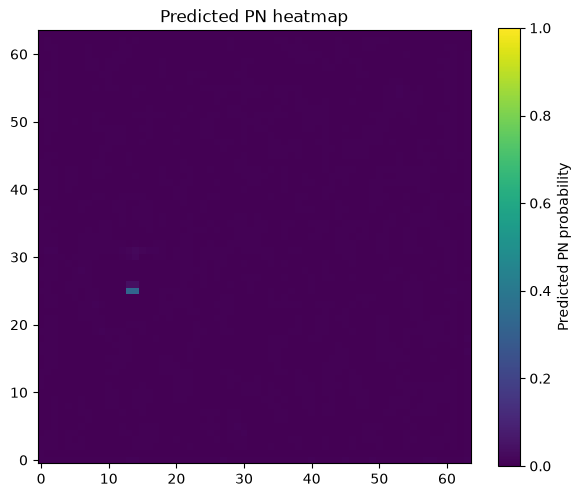

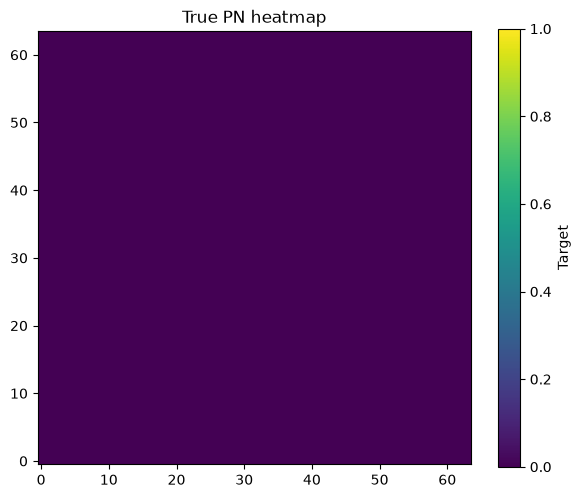

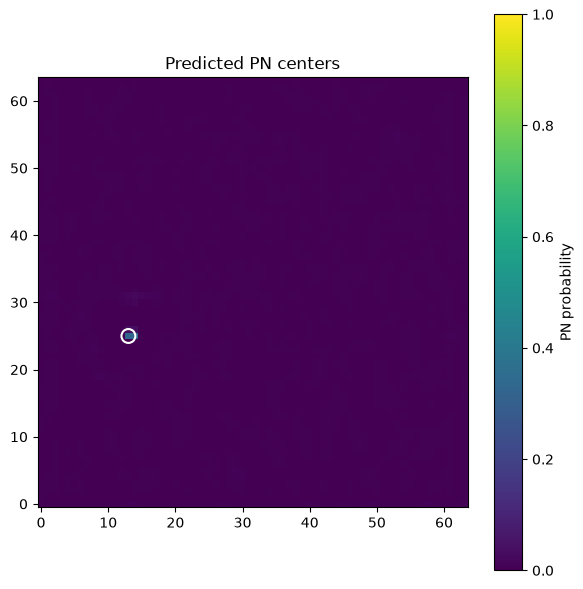

In [18]:
model=keras.models.load_model(
    MODEL_PATH,
    custom_objects={"center_focal_loss":center_focal_loss}
)

test_loss=model.evaluate(test_ds,verbose=1)
print("Best-model test loss:",test_loss)

i=min(50,len(X_test)-1)
pred=model.predict(X_test[i:i+1],verbose=0)[0,:,:,0]
truth=Y_test[i,:,:,0]

plt.figure(figsize=(6,5))
plt.imshow(pred,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="Predicted PN probability")
plt.title("Predicted PN heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
plt.imshow(truth,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="Target")
plt.title("True PN heatmap")
plt.tight_layout()
plt.show()

detections=find_pn_centers(pred,PEAK_THRESHOLD,MIN_DISTANCE)

plt.figure(figsize=(6,6))
plt.imshow(pred,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="PN probability")
if len(detections):
    plt.scatter(detections[:,0],detections[:,1],facecolors="none",edgecolors="white",s=100,linewidths=1.5)
plt.title("Predicted PN centers")
plt.tight_layout()
plt.show()

## Select detection threshold on validation set only

E0000 00:00:1789236103.707267   29058 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


threshold  precision  recall  F1
0.10       0.600      0.975   0.743
0.15       0.666      0.973   0.791
0.20       0.717      0.972   0.825
0.25       0.746      0.968   0.843
0.30       0.774      0.962   0.858
0.35       0.800      0.954   0.870
0.40       0.835      0.940   0.885
0.45       0.868      0.907   0.887
0.50       0.900      0.867   0.883
0.55       0.928      0.808   0.863
0.60       0.943      0.743   0.831
0.65       0.952      0.665   0.783
0.70       0.978      0.584   0.731
0.75       0.990      0.474   0.641
0.80       0.990      0.340   0.506
0.85       0.993      0.224   0.365
0.90       1.000      0.131   0.232
Best validation threshold: 0.45000000000000007


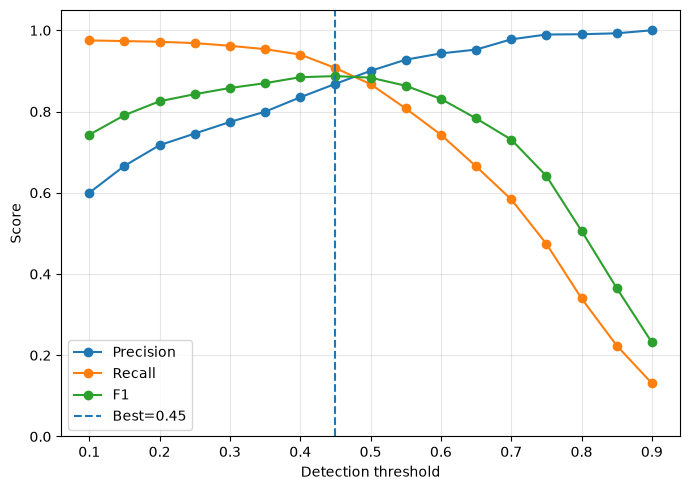

In [19]:
thresholds=np.arange(0.10,0.91,0.05)
results=[]

for threshold in thresholds:
    m=evaluate_detector(
        model,X_val,Y_val,
        threshold=float(threshold),
        min_distance=MIN_DISTANCE,
        match_tolerance=MATCH_TOLERANCE,
        verbose=0
    )
    results.append([threshold,m["precision"],m["recall"],m["f1"]])

results=np.asarray(results,dtype=np.float64)

print("threshold  precision  recall  F1")
for row in results:
    print(f"{row[0]:.2f}       {row[1]:.3f}      {row[2]:.3f}   {row[3]:.3f}")

best_index=np.argmax(results[:,3])
best_threshold=float(results[best_index,0])
print("Best validation threshold:",best_threshold)

plt.figure(figsize=(7,5))
plt.plot(results[:,0],results[:,1],marker="o",label="Precision")
plt.plot(results[:,0],results[:,2],marker="o",label="Recall")
plt.plot(results[:,0],results[:,3],marker="o",label="F1")
plt.axvline(best_threshold,linestyle="--",label=f"Best={best_threshold:.2f}")
plt.xlabel("Detection threshold")
plt.ylabel("Score")
plt.ylim(0,1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final held-out test evaluation

In [20]:
final_metrics=evaluate_detector(
    model,X_test,Y_test,
    threshold=best_threshold,
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE,
    verbose=1
)

print("Final test metrics:")
for key,value in final_metrics.items():
    if key!="localization_errors":
        print(f"{key}: {value}")

print("\nFalse positives by negative type:")
negative_subset_fp_rate(model,X_test,Y_test,types_test,best_threshold)

22/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

E0000 00:00:1789236108.816494   29058 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Final test metrics:
TP: 559
FP: 79
FN: 59
TN: 453
negative_images: 487
negative_images_with_FP: 34
specificity: 0.9301848049281314
false_positive_image_rate: 0.06981519507186858
precision: 0.8761755485893417
recall: 0.9045307443365695
f1: 0.8901273885350318
mean_localization_error: 0.1556350588798523
median_localization_error: 0.0
rmse_localization_error: 0.3945060968399048
std_localization_error: 0.36250901222229004

False positives by negative type:
negative_type     N     image_FP_rate
compact_nonpn     454   0.075
background         33   0.000


## Save normalization and experiment configuration

In [21]:
np.savez(
    NORM_PATH,
    transform=np.asarray("asinh_zscore"),
    line_names=np.asarray(line_names),
    flux_scale=np.float64(FLUX_SCALE),
    asinh_percentile=np.float64(ASINH_PERCENTILE),
    asinh_scale=np.asarray(asinh_scale,dtype=np.float64),
    channel_means=np.asarray(channel_means,dtype=np.float64),
    channel_stds=np.asarray(channel_stds,dtype=np.float64),
    detection_threshold=np.float64(best_threshold)
)

config={
    "seed":SEED,
    "data_path":str(DATA_PATH),
    "model_path":str(MODEL_PATH),
    "batch_size":BATCH_SIZE,
    "initial_learning_rate":LEARNING_RATE,
    "weight_decay":WEIGHT_DECAY,
    "clipnorm":CLIPNORM,
    "max_epochs":MAX_EPOCHS,
    "checkpoint_monitor":"val_loss",
    "flux_scale":FLUX_SCALE,
    "asinh_percentile":ASINH_PERCENTILE,
    "dropout":0.20,
    "peak_threshold_initial":PEAK_THRESHOLD,
    "best_validation_threshold":best_threshold,
    "min_distance":MIN_DISTANCE,
    "match_tolerance":MATCH_TOLERANCE,
    "line_names":[str(x) for x in line_names],
    "train_size":int(len(train_idx)),
    "val_size":int(len(val_idx)),
    "test_size":int(len(test_idx))
}

with open(CONFIG_PATH,"w") as f:
    json.dump(config,f,indent=2)

print("Saved normalization:",NORM_PATH)
print("Saved config:",CONFIG_PATH)

Saved normalization: PN_UNet_normalization_v3.0.npz
Saved config: PN_UNet_training_config_v3.0.json


## Reproducibility checksums

In [22]:
def sha256_file(path,chunk_size=1024*1024):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        while True:
            chunk=f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

print("Dataset SHA256:",sha256_file(DATA_PATH))
print("Model SHA256:",sha256_file(MODEL_PATH))
print("Training complete.")

Dataset SHA256: cfcc362163523c1714ce546769477e4cc8cd43c30252c4016742fb3348c852a4
Model SHA256: d60625e1abaecd08a79fef3705c4af4554c1560f6eaae6fd247e5628825986eb
Training complete.
